# Han et al. (2025): the light curves and lens configurations with lenscape

Han et al. (2025, A&A; [arXiv:2505.22951](https://arxiv.org/abs/2505.22951)) report two planets discovered by
microlensing, **MOA-2022-BLG-091Lb** (four degenerate solutions) and **KMT-2024-BLG-1209Lb** (inner/outer
degeneracy). This notebook redraws the paper's light-curve and lens-geometry figures (Figs. 1, 3, 4, 5 and 7)
with lenscape from the data files shipped with the notebooks. The Δχ² maps (Figs. 2 and 6) have their own
tutorials: `tutorial_first_map_research_note` (the (log *s*, log *q*) map) and `tutorial_alpha_map` (the
trajectory-angle map).

**The data.** The paper does not publish its photometry, but its light-curve figures are vector graphics in which
every point and error bar is stored with its position. `han2025.py` reads them (`lenscape.eps`) and maps device
units to time and magnitude; the result is in `data/moa091_photometry.csv` (plus the public KMTNet baseline
outside the plotted window, marked `source=public`) and `data/kb1209_photometry.csv`. Magnitudes are on an
arbitrary zero point; the source and blend fluxes are free in every fit, so that does not matter.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import config, figures
import han2025 as H

REFIT = False                                   # True: refit the published solutions instead of loading the stored ones
backend = lenscape.make_backend(config.REFINE_BACKEND)
stored = json.load(open("data/han2025_solutions.json"))

## The data

`read_csv` turns a photometry file into a `lenscape.Data` object: one `(t, flux, flux_error)` triple per data
set. For the light-curve figures we use the plotted points only (`source == "figure"`), as the paper does.

In [2]:
def read_csv(path, names, source="figure", zp=22.0):
    skip = sum(1 for line in open(path) if line.startswith("#"))      # the comment lines at the top
    rows = np.genfromtxt(path, delimiter=",", names=True, dtype=None, encoding="utf-8", skip_header=skip)
    sets = {}
    for name in names:
        r = rows[(rows["set"] == name) & (rows["source"] == source)]
        flux = 10 ** (-0.4 * (r["mag"] - zp))
        sets[name] = (r["t"], flux, flux * 0.4 * np.log(10) * r["mag_err"])
    return lenscape.Data.from_sets(sets)

moa_plotted = read_csv("data/moa091_photometry.csv", ["KMTA22", "KMTC22", "KMTS22", "MOA22"])
kb_plotted = read_csv("data/kb1209_photometry.csv", ["KMTA", "KMTC", "KMTS", "OGLE", "LCOA", "LCOC"])
print(moa_plotted, kb_plotted, sep="\n")

Data(716 points, t 9630.86 .. 9706.12, sets {'KMTA22': 61, 'KMTC22': 305, 'KMTS22': 105, 'MOA22': 245})
Data(580 points, t 444.51 .. 537.37, sets {'KMTA': 57, 'KMTC': 118, 'KMTS': 93, 'OGLE': 29, 'LCOA': 85, 'LCOC': 198})


## Solutions

Started from the paper's Tables 2 and 3 (with lenscape's sign convention for *u*₀), fitted to the plotted data;
the stored vectors are those fits (`REFIT = True` repeats them, about a minute).

In [3]:
paper_moa = {"A": (9657.729, 0.02565, 34.68, 1.0029, 4.55e-3, 4.632, -3.0),
             "B": (9657.785, 0.02614, 34.51, 1.0033, 4.36e-3, 4.354, -3.0),
             "C": (9657.699, 0.02642, 34.53, 1.0132, 3.38e-3, 4.811, -3.0),
             "D": (9657.706, 0.02590, 34.54, 1.0195, 4.10e-3, 4.745, -3.0)}
paper_kb = {"Inner": (491.126, 0.0257, 70.11, 1.0599, 3.33e-3, 4.5957, np.log10(0.75e-3)),
            "Outer": (491.141, 0.0249, 73.13, 0.9724, 2.90e-3, 4.5294, np.log10(0.73e-3))}
vec = lambda t0, u0, tE, s, q, al, lr: np.array([t0, -u0, tE, np.log10(s), np.log10(q), al, lr])

if REFIT:
    moa = {k: lenscape.fit_full(moa_plotted, vec(*v))[1] for k, v in paper_moa.items()}
    kb = {k: lenscape.fit_full(kb_plotted, vec(*v))[1] for k, v in paper_kb.items()}
else:
    moa = {k: np.array(v) for k, v in stored["MOA-2022-BLG-091"]["plotted"].items()}
    kb = {k: np.array(v) for k, v in stored["KMT-2024-BLG-1209"]["plotted"].items()}

chi = {k: lenscape.model.chi2(backend, p, moa_plotted) for k, p in moa.items()}
print("MOA-2022-BLG-091 (paper: Sol B best; A +1.1, D +5.0, C +6.7)")
for k, p in moa.items():
    print(f"  Sol {k}: dchi2 {chi[k] - min(chi.values()):5.1f}   s {10 ** p[3]:.4f}  q {10 ** p[4] * 1e3:.2f}e-3  alpha {p[5]:.3f}")
chi = {k: lenscape.model.chi2(backend, p, kb_plotted) for k, p in kb.items()}
print("KMT-2024-BLG-1209 (paper: outer better by 2.0)")
for k, p in kb.items():
    print(f"  {k}: dchi2 {chi[k] - min(chi.values()):5.1f}   s {10 ** p[3]:.4f}  q {10 ** p[4] * 1e3:.2f}e-3  "
          f"tE {p[2]:.1f}  rho {10 ** p[6] * 1e3:.2f}e-3")

MOA-2022-BLG-091 (paper: Sol B best; A +1.1, D +5.0, C +6.7)
  Sol A: dchi2   1.1   s 1.0023  q 4.27e-3  alpha 4.621
  Sol B: dchi2   0.0   s 1.0047  q 4.00e-3  alpha 4.413
  Sol C: dchi2   7.4   s 1.0130  q 3.36e-3  alpha 4.818
  Sol D: dchi2   5.4   s 1.0187  q 3.90e-3  alpha 4.749
KMT-2024-BLG-1209 (paper: outer better by 2.0)
  Inner: dchi2   0.8   s 1.0608  q 3.28e-3  tE 72.5  rho 0.71e-3
  Outer: dchi2   0.0   s 0.9714  q 2.86e-3  tE 75.2  rho 0.70e-3


## Figure 1 — light curve of MOA-2022-BLG-091

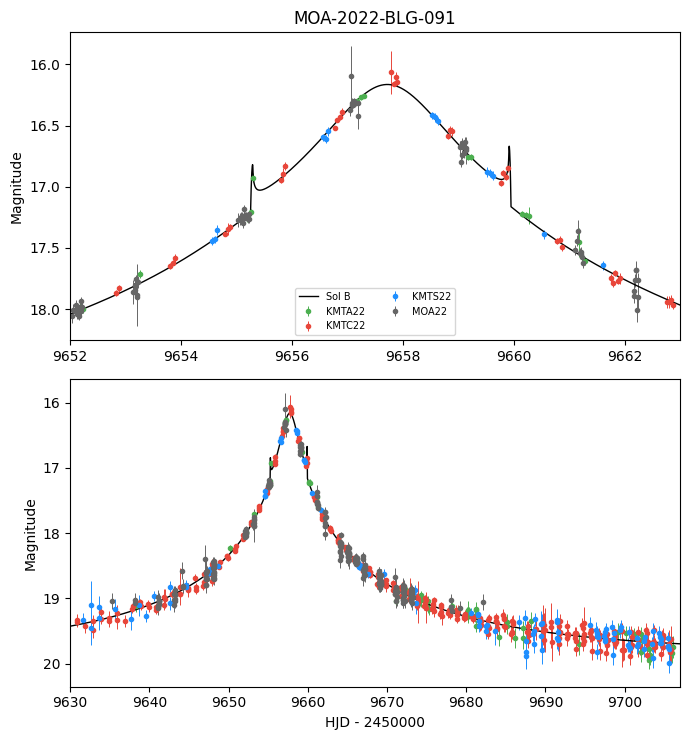

In [4]:
H.plot_two_panels(backend, [("Sol B", "-", moa["B"])], moa_plotted, zoom=(9652, 9663), overall=(9630, 9707),
                  ref=moa_plotted.names.index("KMTC22"), title="MOA-2022-BLG-091");

## Figure 3 — the four degenerate solutions of MOA-2022-BLG-091

The planetary anomaly with the four solutions A–D, which differ in the trajectory angle and in the side on
which the source passes the caustic; the insets show where the models differ.

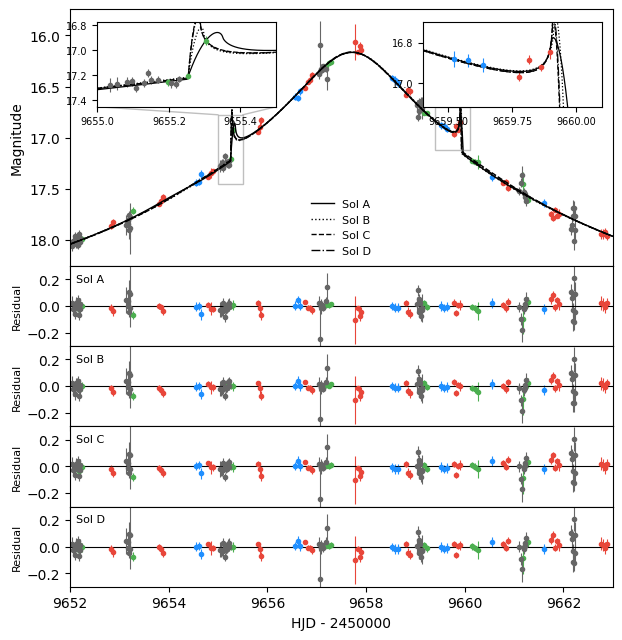

In [5]:
figures.plot_lightcurve(backend, [moa[k] for k in "ABCD"], moa_plotted, labels=[f"Sol {k}" for k in "ABCD"],
                        window=(9652, 9663), insets=[(9655.0, 9655.5), (9659.4, 9660.1)],
                        ref=moa_plotted.names.index("KMTC22"), colors=H.COLORS);

## Figure 4 — lens configurations of MOA-2022-BLG-091

The paper draws the configuration mirrored about the binary axis (`mirror=True`); the light curve is the same.

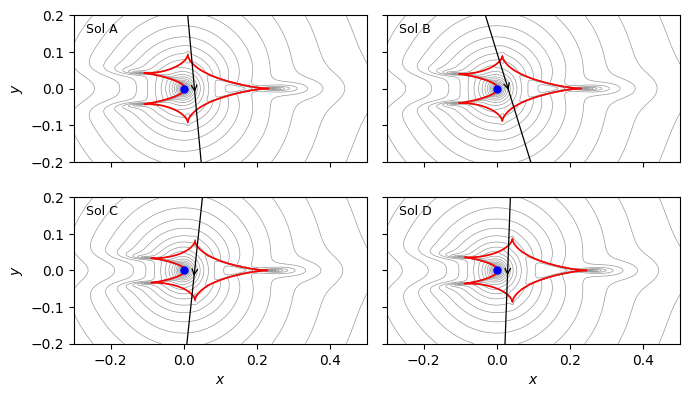

In [6]:
figures.plot_geometry([moa[k] for k in "ABCD"], labels=[f"Sol {k}" for k in "ABCD"],
                      extent=(-0.3, 0.5, -0.2, 0.2), mirror=True);

## Figure 5 — light curve of KMT-2024-BLG-1209

With the outer binary-lens solution and, for comparison, the best single-lens (1L1S) model.

chi2: 2L1S outer 580.7, 1L1S 1419.7


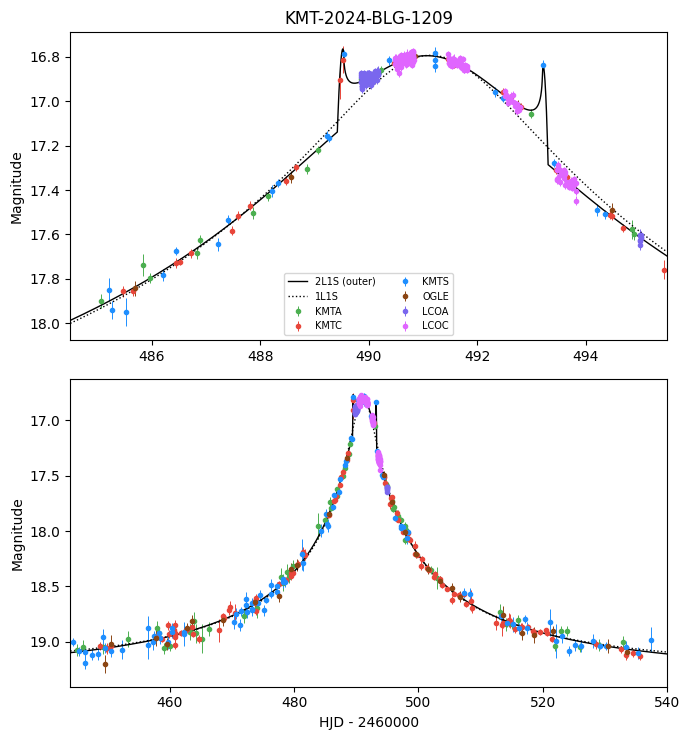

In [7]:
from lenscape.optimize import minimize
from lenscape import single
def chi2_1l1s(x, d=kb_plotted):
    A = single.lc_1l1s(x[0], x[1], abs(x[2]), 10 ** x[3], d.t, 0.0)
    fs, fb = lenscape.model.fluxes(A, d)
    return float((((d.f - fs[d.idx] * A - fb[d.idx]) / d.e) ** 2).sum())
r = minimize(chi2_1l1s, [491.1, 0.03, 70.0, -3.0], method="Nelder-Mead", options=dict(maxfev=4000, adaptive=True))
x1 = r.x
ref = kb_plotted.names.index("KMTC")
A_1l1s = lambda t: single.lc_1l1s(x1[0], x1[1], abs(x1[2]), 10 ** x1[3], t, 0.0)
fs1, fb1 = lenscape.model.fluxes(A_1l1s(kb_plotted.t), kb_plotted)
one = lambda t: 22 - 2.5 * np.log10(fs1[ref] * A_1l1s(t) + fb1[ref])     # on the reference set's (KMTC) scale
print(f"chi2: 2L1S outer {lenscape.model.chi2(backend, kb['Outer'], kb_plotted):.1f}, 1L1S {r.fun:.1f}")
H.plot_two_panels(backend, [("2L1S (outer)", "-", kb["Outer"]), ("1L1S", ":", one)], kb_plotted,
                  zoom=(484.5, 495.5), overall=(444, 540), ref=ref, title="KMT-2024-BLG-1209");

## Figure 7 — lens configurations of KMT-2024-BLG-1209

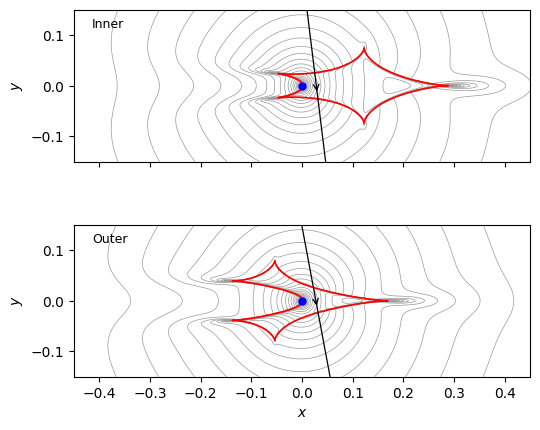

In [8]:
figures.plot_geometry([kb["Inner"], kb["Outer"]], labels=["Inner", "Outer"], ncols=1,
                      extent=(-0.45, 0.45, -0.15, 0.15), mirror=True, figsize=(5.5, 5));

The Δχ² maps of both events (Figs. 2 and 6 of the paper) are the subject of the two tutorial notebooks; the
MOA-2022-BLG-091 maps there use the same CSV with the public baseline added (`source == "public"`), which
constrains the blending.